# PRE-PROCESSING OF THE STUDENT DATASET

This Notebook explores the .csv dataset used to detect patients with pathologies.

GOALS:
- Missing value detection
- Duplicate identification
- File reorganization
- Clustering

In [35]:
import pandas as pd
import sklearn as skl
import matplotlib.pyplot as plt
import numpy as np
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize


df = pd.read_csv('../Student_Dataset.csv')

print("Aperçu des premières lignes (df.head) :")
df

Aperçu des premières lignes (df.head) :


,1,On uneven paths the heel feels wobbly side‑to‑side. Slanted pavements bring a quick aching shift under the ankle when I step.
2,0x000000,"The feverish feeling eased, but I’m now breath..."
3,0x000000,"While working in the garden, I touched a metal..."
4,A short sprint brought on a twinge in the midd...,NaN
5,0x000000,I accidentally left my hand on a hot mug for a...
6,A sudden twist while reaching for a bag made o...,NaN
...,...,...
1007,0x000000,I slammed my fingertip in a drawer. The tip is...
1008,0x000000,I woke up with a throbbing pain in my left ear...
1009,0x000000,"During the summer, my throat gets itchy and I ..."
1010,Pushing off during a brisk walk makes the big ...,NaN


### Conclusion

We have noticed irregularities in the file. Some lines contain two columns, while others have three. There are also instances of "0x000000" and some missing data. "0x000000" codes appear in place of some testimonials. We can also say that there are tree main column in this dataset: `ID`, `Code` and `Testimonials`.

## Cleaning of the dataset

In this block we apply robust cleaning and pre-processing with NLTK:
- Correct malformatted rows by moving non 0x codes into `Testimonies` and normalizing `Code` to `0x000000`.
- Remove rows with empty testimonies and drop duplicated text.
- Convert to lowercase, remove punctuation and non-alpha characters, and tokenize.
- Remove English stop words using NLTK stopword list.
- Apply lemmatization with WordNet (instead of simple suffix stripping) to keep root forms.
- Replace any remaining empty testimonials with `0x000000` and save a cleaned CSV.

In [36]:
nltk.download('stopwords', quiet=True)
nltk.download('punkt', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

# Lecture du fichier avec gestion des lignes mal formatées

df_clean = pd.read_csv('../Student_Dataset.csv', header=None, names=['ID', 'Code', 'Testimonies'], on_bad_lines='skip')

# Correction des lignes où Code n'est pas sous forme 0x... : répartition dans Testimonies
mask_decalage = ~df_clean['Code'].astype(str).str.contains('0x', na=False)
df_clean.loc[mask_decalage, 'Testimonies'] = df_clean.loc[mask_decalage, 'Code']
df_clean.loc[mask_decalage, 'Code'] = '0x000000'

# Nettoyage basique et suppression des doublons

df_final = df_clean.dropna(subset=['Testimonies']).copy()
df_final = df_final.drop_duplicates(subset=['Testimonies'])

df_final['Code'] = df_final['Code'].fillna('0x000000')

def clean_text(text):
    if not isinstance(text, str) or text.strip() == '':
        return '0x000000'

    # lower, suppression ponctuation, tokenization
    text = text.lower()
    text = re.sub(r'[^a-z\s]', ' ', text)

    tokens = word_tokenize(text)

    # stopwords et lemmatisation
    stop_words_set = set(stopwords.words('english'))
    lemmatizer = WordNetLemmatizer()
    cleaned_tokens = [lemmatizer.lemmatize(tok) for tok in tokens if tok not in stop_words_set and len(tok) > 1]

    cleaned = ' '.join(cleaned_tokens).strip()
    return cleaned if cleaned else '0x000000'

# Application du nettoyage

df_final['Testimonies'] = df_final['Testimonies'].apply(clean_text)

# Suppression des lignes tombées à 0x000000 si on le souhaite
# df_final = df_final[df_final['Testimonies'] != '0x000000']

# Enregistrement final

df_final.to_csv('Student_Dataset_Cleaned.csv', index=False)

# Métriques de nettoyage
print('Nombre de lignes après nettoyage :', len(df_final))
print('Codes distincts :', df_final['Code'].nunique())
df_final


Nombre de lignes après nettoyage : 1002
Codes distincts : 1


,ID,Code,Testimonies
0,1,0x000000,uneven path heel feel wobbly side side slanted...
1,2,0x000000,feverish feeling eased breathing faster dry ex...
2,3,0x000000,working garden touched metal grill stove left ...
3,4,0x000000,short sprint brought twinge middle back thigh ...
4,5,0x000000,accidentally left hand hot mug minute feel ten...
...,...,...,...
1006,1007,0x000000,slammed fingertip drawer tip throbbing nail lo...
1007,1008,0x000000,woke throbbing pain left ear feel like blockag...
1008,1009,0x000000,summer throat get itchy start coughing especia...
1009,1010,0x000000,pushing brisk walk make big toe joint feel sti...


## Data vectorization

In this section, we transform the cleaned textual testimonies into numerical vectors suitable for machine learning algorithms. We use the TF-IDF (Term Frequency-Inverse Document Frequency) vectorization technique to convert text into a sparse matrix where each row represents a testimony and each column represents a word's importance in the corpus.

To improve clustering performance and reduce computational complexity, we apply dimensionality reduction using Truncated SVD (Singular Value Decomposition), reducing the high-dimensional TF-IDF space to 100 components while preserving the most important variance (approximately 30% explained variance).

Finally, we normalize the vectors using L2 normalization to prepare for distance-based clustering algorithms like K-means, which work better with cosine similarity in text data. This preprocessing step ensures that testimonies with similar thematic content (e.g., related symptoms, experiences, or pathology descriptions) are positioned closer in the vector space.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize
from sklearn.decomposition import TruncatedSVD

vectorizer = TfidfVectorizer(max_df=0.8, min_df=2, stop_words='english')
X = vectorizer.fit_transform(df_final['Testimonies'])

# Réduction de dimensions pour améliorer la séparation des clusters
n_components = 100
svd = TruncatedSVD(n_components=n_components, random_state=42)
X_reduced = svd.fit_transform(X)

# Normalisation pour utiliser la distance cosinus
X_normalized = normalize(X_reduced, norm='l2', axis=1)

print(f"Matrice TF-IDF : {X_normalized.shape}")
print(f"Variance expliquée : {svd.explained_variance_ratio_.sum():.3f}")

Matrice TF-IDF réduite et normalisée : (1002, 100)
Variance expliquée : 0.433


There is a visual representation of the 10 words with the most weight and the 10 words with the less weight.

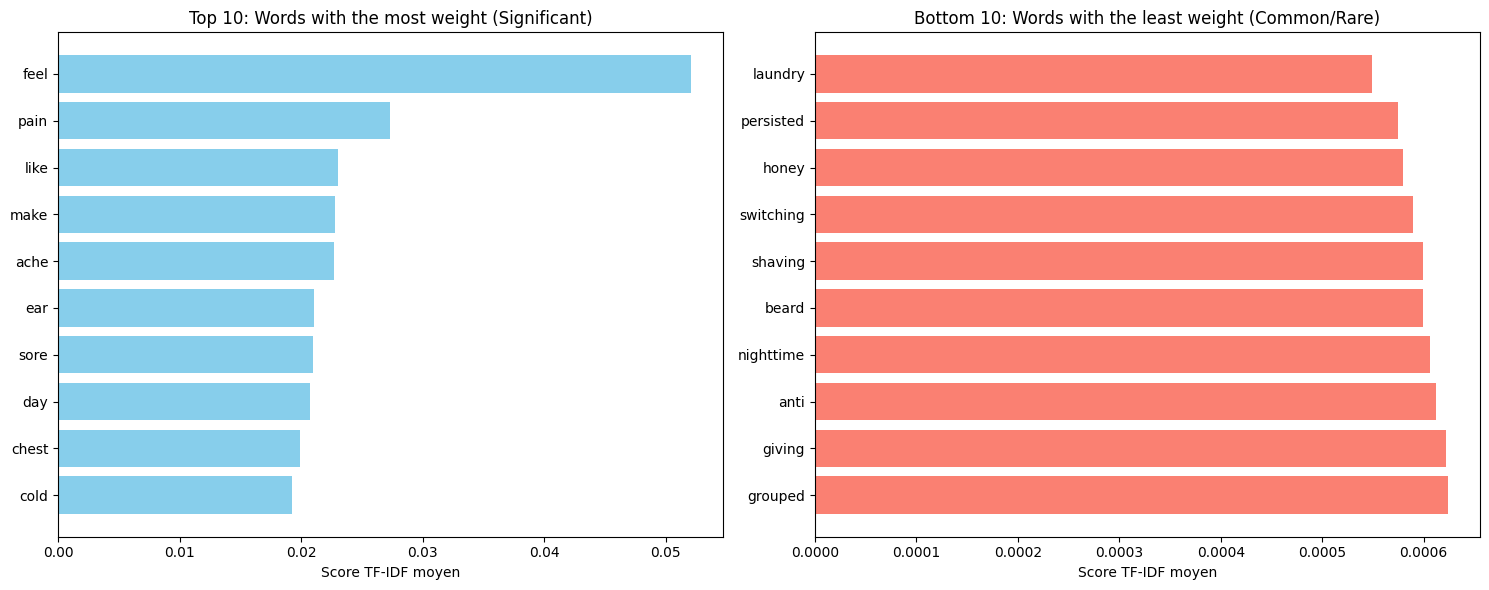

In [38]:
feature_names = vectorizer.get_feature_names_out()
mean_weights = np.asarray(X.mean(axis=0)).ravel()

df_weights = pd.DataFrame({'word': feature_names, 'weight': mean_weights})
df_top = df_weights.sort_values(by='weight', ascending=False).head(10)
df_bottom = df_weights.sort_values(by='weight', ascending=True).head(10)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

ax1.barh(df_top['word'], df_top['weight'], color='skyblue')
ax1.set_title('Top 10: Words with the most weight (Significant)')
ax1.invert_yaxis()
ax1.set_xlabel('Score TF-IDF moyen')

ax2.barh(df_bottom['word'], df_bottom['weight'], color='salmon')
ax2.set_title('Bottom 10: Words with the least weight (Common/Rare)')
ax2.invert_yaxis()
ax2.set_xlabel('Score TF-IDF moyen')

plt.tight_layout()
plt.show()

## Clustering of the data

In this section, we apply unsupervised clustering to group similar student testimonies based on their thematic content. We use the K-means algorithm, which partitions the data into k clusters by minimizing the within-cluster sum of squares.

To determine the optimal number of clusters k, we employ two complementary evaluation methods:
- **Elbow Method (Knee Method)**: Analyzes the inertia (within-cluster variance) as k increases, looking for the "elbow" point where adding more clusters yields diminishing returns.
- **Silhouette Analysis**: Measures how similar objects are to their own cluster compared to other clusters, with higher scores indicating better separation.

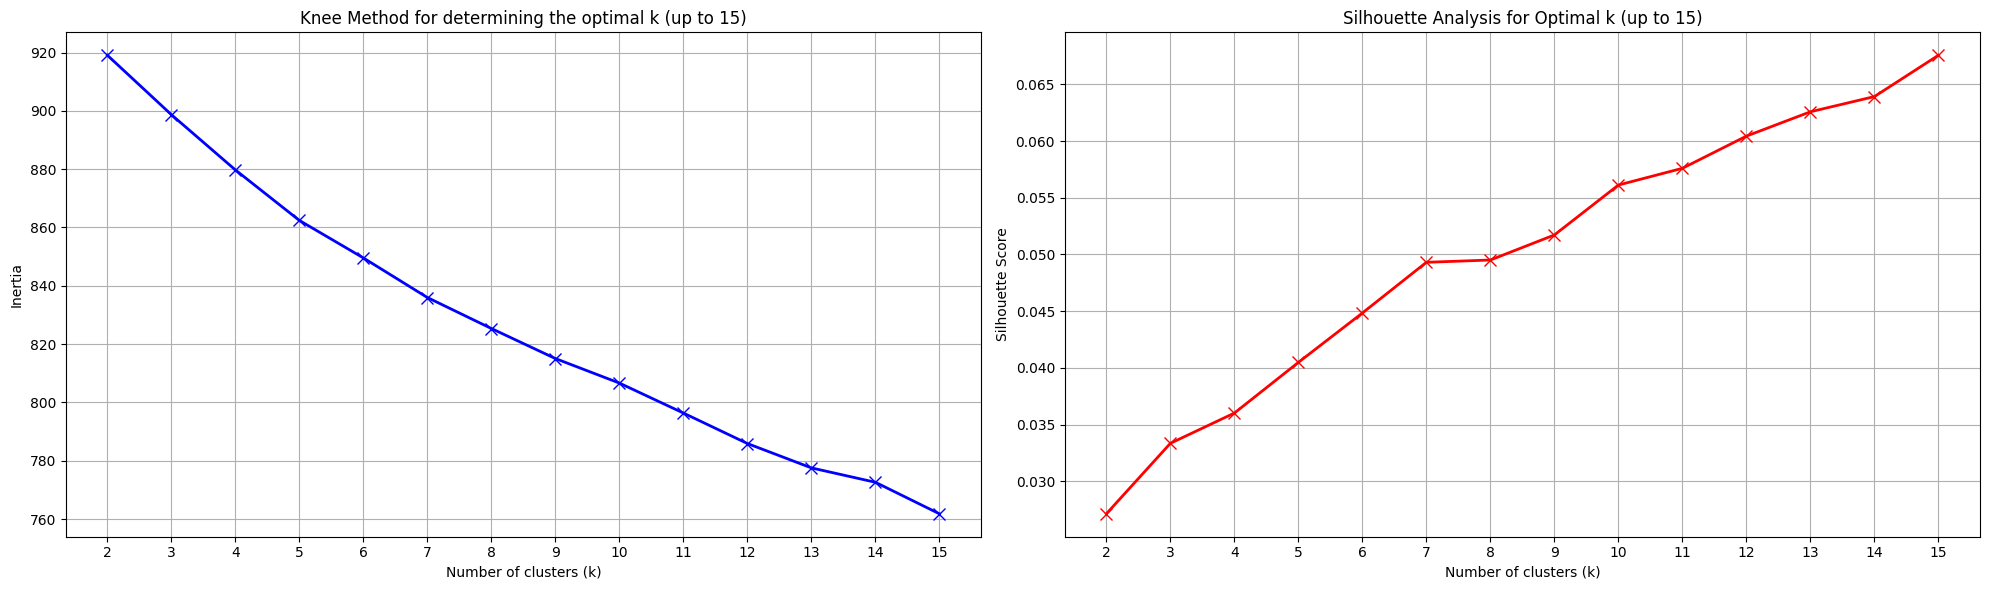

Optimal k based on knee method: 7
Silhouette score for k=7: 0.049


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertie = []
silhouette_scores = []
K_range = range(2, 16)  # De 2 à 15 clusters

for k in K_range:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_normalized)
    inertie.append(model.inertia_)
    score = silhouette_score(X_normalized, labels, metric='euclidean')
    silhouette_scores.append(score)

# Graphiques côte à côte
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 6))

# Elbow plot
ax1.plot(K_range, inertie, 'bx-', markersize=8, linewidth=2)
ax1.set_xticks(K_range)
ax1.set_xlabel('Number of clusters (k)')
ax1.set_ylabel('Inertia')
ax1.set_title('Knee Method for determining the optimal k (up to 15)')
ax1.grid(True)

# Silhouette plot
ax2.plot(K_range, silhouette_scores, 'rx-', markersize=8, linewidth=2)
ax2.set_xticks(K_range)
ax2.set_xlabel('Number of clusters (k)')
ax2.set_ylabel('Silhouette Score')
ax2.set_title('Silhouette Analysis for Optimal k (up to 15)')
ax2.grid(True)

plt.tight_layout()
plt.show()

### Conclusion

After analyzing k values from 2 to 15, we selected k=7 as it provides a good balance between cluster compactness and separation. This choice groups the testimonies into 7 distinct thematic categories, potentially representing different types of student experiences, symptom patterns, or pathology-related narratives in the dataset.

In [63]:
kmeans_final = KMeans(n_clusters=7, random_state=42, n_init=10)

df_final['Cluster_Predit'] = kmeans_final.fit_predict(X_normalized)

print("Distribution of testimonies across the 7 clusters:")
print(df_final['Cluster_Predit'].value_counts().sort_index().to_string())

# Calcul du score silhouette final
final_silhouette = silhouette_score(X_normalized, df_final['Cluster_Predit'], metric='euclidean')
print(f"\nFinal Silhouette Score: {final_silhouette:.3f}")

distances = kmeans_final.transform(X_normalized)

# Analyse des thèmes par cluster
feature_names = vectorizer.get_feature_names_out()

for i in range(7):
    cluster_indices = df_final['Cluster_Predit'] == i
    if cluster_indices.sum() > 0:
        # Moyenne des scores TF-IDF pour le cluster
        cluster_tfidf = X[cluster_indices.values].mean(axis=0).A1
        # Top 5 mots avec les scores les plus élevés
        top_indices = cluster_tfidf.argsort()[-5:][::-1]
        top_words = [feature_names[idx] for idx in top_indices]
        print(f"CLUSTER {i} : {', '.join(top_words)}")
    else:
        print(f"CLUSTER {i} : No items found")

print("\n" + "-"*60)

Distribution of testimonies across the 7 clusters:
Cluster_Predit
0    113
1    126
2    265
3     74
4     58
5    281
6     85

Final Silhouette Score: 0.049
CLUSTER 0 : hot, skin, blister, red, small
CLUSTER 1 : pain, ear, feel, head, throbbing
CLUSTER 2 : feel, chest, breath, cough, feeling
CLUSTER 3 : itchy, rash, new, raised, hive
CLUSTER 4 : blood, doctor, thirsty, weight, losing
CLUSTER 5 : make, ache, feel, deep, sore
CLUSTER 6 : throat, nose, felt, mild, cough

------------------------------------------------------------


## Clusters visualisations

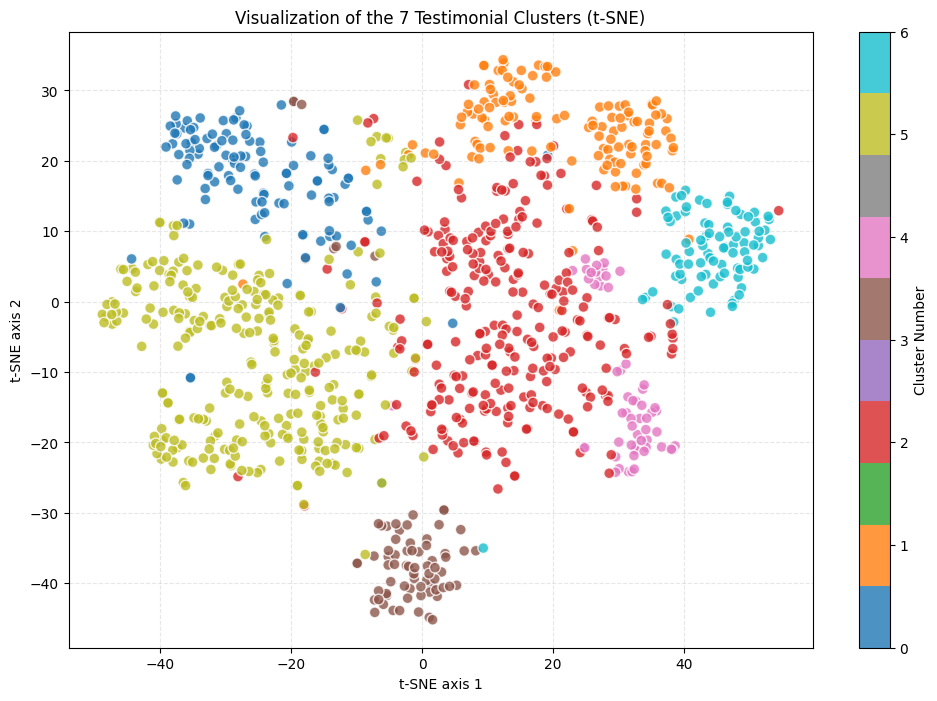

In [60]:
from sklearn.manifold import TSNE

# Utilisation de t-SNE pour une meilleure visualisation des clusters
tsne = TSNE(n_components=2, random_state=42, perplexity=30, max_iter=1000)
coords = tsne.fit_transform(X_normalized)

clusters_couleurs = df_final['Cluster_Predit']

plt.figure(figsize=(12, 8))

scatter = plt.scatter(coords[:, 0], coords[:, 1], 
                      c=clusters_couleurs, 
                      cmap='tab10',  # Pour 7 clusters
                      alpha=0.8, 
                      edgecolors='w', 
                      s=60)

plt.title("Visualization of the 7 Testimonial Clusters (t-SNE)")
plt.xlabel("t-SNE axis 1")
plt.ylabel("t-SNE axis 2")

# Légende numérotée de 0 à 6
plt.colorbar(scatter, ticks=range(7), label="Cluster Number")
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()